# Les émeutes

# Contexte du projet
Ces dernières années, les émeutes en France ont vu leur fréquence augmenter, avec les Gilets Jaunes d'abord en 2017-2018, les émeutes liées à la mort de Nahel en 2023 ensuite, ou encore les émeutes en Nouvelle-Calédonie en 2024. Ces émeutes ont causé des pertes assurantielles importantes, notamment pour les acteurs assurant les collectivités, qui se répercutent aujourd'hui sur une hausse des prix des contrats avec une police émeute, ce qui rend difficile pour certaines communes de s'assurer face à ce risque émeute.

Une réforme législative entrant en vigueur en janvier 2027 impose donc aux assureurs de couvrir les émeutes dans les mêmes conditions que les contrats incendie, et pour compenser prévoit la mise en place d’un fonds de réassurance garanti par l’Etat. Du point de vue des réassureurs, pour aider les cédantes à composer avec cette réforme et statuer quant au maintien des contrats via la réassurance traditionnelle, il faut prédire le risque émeute pour les prochaines années.

Le CESDIP a produit un rapport (disponible [ici](https://ierdj.fra1.digitaloceanspaces.com/media_library/2026/07/23.95_EMEUTES_URBAINES_rapport.pdf)) suite aux émeutes de 2023, qui comporte une partie quantitative sur les caractéristiques des communes ayant subi des émeutes puis une partie qualitative sur les profils des émeutiers. La partie quantitative met en évidence l'importance du taux d'inactivité des jeunes ainsi que de la ségrégation de la commune. Les résultats sont rapportés aux études précédentes de Hugues Lagrange sur les émeutes de 2005 et de Oberti et Guillaume Le Gall sur les émeutes de 2023, en montrant que les résultats des études, s'ils portent des conclusions similaires quant aux liens avec l'emploi et la ségrégation, gardent cependances des dissemblances peu comparables du fait des méthodes retenues dans chacune des études.

Un problème émerge alors : quelles variables socio-démographiques pourraient participer à la prédiction du risque émeute ? Les variables identifiées en 2005 et en 2023 sont-elles propres aux évènements étudiés ou peuvent elles généralisées aux évènements émeute de manière plus générale ?

Nous analyserons donc des données sur des évènements émeutes postérieurs à 2023, en analysant leur lien avec le taux d'inactivité des jeunes d'une part et la présence de QPV d'autre part, relatifs aux territoires concernés par ces évènements.

Nous essaierons aussi de lier les évènements émeutes entre eux dans le temps en les comparant avec les données Google Trends pour identifier des clusters à l'échelle de la France, utile au secteur assurantiel pour la définition légale d'un évènement émeute "france entière" afin de déclencher une police de réassurance pour un sinistre émeute.

# Plan:
- extraction des bases de données intérmédiaires :
    - GDELT Project via Big Query
    - GDELT Cloud
- Récupération des données:
    - GDELT
    - Google Trends
- Nettoyage
- Comparaison Gdelt, Google Trends
- Les données sociales:
    - Taux d'Inactivité
    - Quartier prioritaires
- Peut-on trouver une relation ?
- Limites et Conclusion


In [1]:
# Quelques modules à importer : après avoir installé au préalable "pip install google-cloud-bigquery db-dtypes"
import os, json, s3fs
from google.cloud import bigquery
from google.oauth2 import service_account

# Quelques fonctions à importer
from GDELT_data.big_query_data.req_2023 import requete_bigquery
from GDELT_data.cloud_data.req_all_bywindow import requete_gcloud

# accès stockage
fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})

# Extraction des bases de données intermédiaires

Quelles sont les données disponibles sur les émeutes en France ? 
Nous avons cherché à obtenir des données spatiales et temporelles sur des évènements catégorisés comme des émeutes par le passé.

## Base de données du GDELT Project via Big Query
Nous nous sommes intéressés dans un premier temps aux données du GDELT Project, qui analyse des articles de presses publiés partout dans le monde sur des sujets très variés et les regroupe dans une même base de données en open data. Elle contient en particulier des évènements concernant les manifestations et plus précisément encore les émeutes.

Face à la grande taille de cette base de données, nous avons utilisé le service Google Cloud BigQuery pour effectuer un filtre sur les émeutes en France via une requête SQL, et nous sommes pour cela passés par un compte de services. Pour éviter de scanner un trop gros volume de données et ainsi dépasser la limite d'utilisation gratuite de Google BigQuery de 1 To de données scannées, nous avons utilisé le partitionnement de la base sur la date, pour extraire seulement les évènements émeutes en France postérieurs à 2023, en filtrant sur les colonnes qui nous paraissaient utiles.

En effet, la Base du GDELT project contient 61 colonnes qui ne sont pas toutes utiles pour notre approche. Dans cette base, un évènements est décrit comme une interaction entre au plus deux acteurs, avec des informations sur l'interaction et sur chacun des deux acteurs. La documentation est disponible [ici](https://data.gdeltproject.org/documentation/GDELT-Event_Codebook-V2.0.pdf). 

Nous avons donc choisi pour notre analyse de conserver :

informations générales :
- GLOBALEVENTID : identifiant de l'évènement, pour d'éventuelles jointures ultérieures (pour rajouter les colonnes écartées par exemple)
- SOURCEURL : l'URL de l'article source sur lequel se base le codage machine de l'évènement (pour pouvoir comprendre la source du codage de l'évènement et vérifier qualitativement la qualité du codage de certains évènements)
- SQLDATE : la date

informations sur les acteurs 1 (resp. 2 en remplaçant 1 par 2 dans les noms de variables) :
- Actor1CountryCode : le code CAMEO pour le pays de l'acteur 1
- Actor1Name : le nom de l'acteur 1
- Actor1Type1Code, Actor1Type2Code, Actor1Type3Code : des champs qui précisent la catégorie de l'acteur 1
- Actor1Geo_FeatureID : un code GNIS de la localisation de l'acteur lorsque la précision le permet, une chaine de caractère sinon (peut permettre des jointures spatiales)

informations sur la source et son environnement médiatique
- NumArticles : le nb de sources qui parlent du meme évènement dans un ontervalle de temps resseré (pour évaluer l'importance de l'évènement)
- AvgTone : positif si les articles qui parlent de cet évènement en parle en moyenne positivement (mesure subjective)

informations sur la localisation de l'évènement :
- ActionGeo_Type : la précision du géocodage, 4 désigne une ville hors US, 5 un découpage administratif de niveau 1 (région) hors US
- ActionGeo_CountryCode : l'état dans lequel se déroule l'évènement
- ActionGeo_FullName : une chaine de caractère dénommant le lieu
- ActionGeo_ADM1Code : présente un code FIPS10-4 (en France, un équivalent de la région)
- ActionGeo_ADM2Code : présente un code GAUL (en France, un équivalent d'un département)
- ActionGeo_Lat, ActionGeo_Long : latitude et longitude, souvent un centroide de l'élément de localisation le plus précis (centroide de la région lorsque l'adm2 n'est pas renseigné par exemple)
- ActionGeo_FeatureID : un code GNIS lorsque la précision le permet, une chaine de caractère sinon (peut permettre des jointures spatiales)

In [2]:
# paramètre requête
sql = """
SELECT 
    GLOBALEVENTID, SOURCEURL, SQLDATE, 
    Actor1CountryCode, Actor1Name, Actor1Type1Code, Actor1Type2Code, Actor1Type3Code, 
    Actor2CountryCode, Actor2Name, Actor2Type1Code, Actor2Type2Code, Actor2Type3Code, 
    NumArticles, AvgTone, 
    Actor1Geo_FeatureID, Actor2Geo_FeatureID, ActionGeo_FeatureID,
    ActionGeo_Type, ActionGeo_CountryCode, ActionGeo_FullName, ActionGeo_ADM1Code, ActionGeo_ADM2Code, ActionGeo_Lat, ActionGeo_Long
FROM 
    `gdelt-bq.gdeltv2.events_partitioned`
WHERE _PARTITIONDATE >= '2023-01-01'
  AND EventBaseCode = '145'
  AND ActionGeo_CountryCode = 'FR'
"""

requete_bigquery(sql)

Cette requête a déjà été effectuée et son résultat a été stocké à des fins de reproductibilité.
Le résultat est disponible au format parquet à l'adresse vgounot/diffusion/2023_gcloud_emeutes.parquet.


Pour reproduire l'extraction, après avoir configuré un compte de service et l'avoir lié à sa clé en variable d'environnement, il faut ajouter en argument de `requete_bigquery()` le paramètre `path` avec un emplacement de stockage fs fonctionnel.

De plus, l'extraction ayant été réalisée le 10 nov 2026, pour avoir une base réellement identique il faudrait filtrer sur DATEADDED avec `sql_repro`, comme par exemple ci-après :

In [3]:
sql_repro = """
SELECT 
    GLOBALEVENTID, SOURCEURL, SQLDATE, 
    Actor1CountryCode, Actor1Name, Actor1Type1Code, Actor1Type2Code, Actor1Type3Code, 
    Actor2CountryCode, Actor2Name, Actor2Type1Code, Actor2Type2Code, Actor2Type3Code, 
    NumArticles, AvgTone, 
    Actor1Geo_FeatureID, Actor2Geo_FeatureID, ActionGeo_FeatureID,
    ActionGeo_Type, ActionGeo_CountryCode, ActionGeo_FullName, ActionGeo_ADM1Code, ActionGeo_ADM2Code, ActionGeo_Lat, ActionGeo_Long
FROM 
    `gdelt-bq.gdeltv2.events_partitioned`
WHERE _PARTITIONDATE >= '2023-01-01'
  AND DATEADDED <= 20261110143229
  AND EventBaseCode = '145'
  AND ActionGeo_CountryCode = 'FR'
"""

# requete_bigquery(sql_repro, path="à remplacer")

En explorant rapidement les données, on s'aperçoit que la qualité des données est souvent assez variable et peu précise géographiquement. Par exemple, une donnée du 20 octobre 2026 est codée à Paris lorsque l'article commente des émeutes à Milan décrivant leur lien avec les émeutes en France. Pour s'affranchir de ce problème, une idée peut être de filtrer sur les évènements ayant un ActionGeo_Type de valeur 4 (et éventuellement aussi ceux de valeur 5).
On s'aperçoit aussi que des évènements encodés comme émeute concernent en réalité par exemple la mise en place d'un couvre feu par le premier ministre dans les grandes villes, ce qui n'est pas un évènement émeute au sens de notre analyse.

## Base de données proposée par GDELT Cloud
Face à la qualité de ces données, nous avons exploré une deuxième base de données proposée par GDELT Cloud, accessible via une API sous un "free" plan, qui semble proposer des données de bien meilleure qualité, tant spatialement que sur le lien réel de l'évènement avec une émeute, mais qui ne propose que des évènements se déroulant après mars 2026.
GDELT Cloud nous autorise à partager les données extraites et les résultats sous la license du "academic plan" dans le cadre de ce projet.

Cette API renvoie des données sous la forme d'un fichier JSON limité à 100 évènements sur une fenêtre temporelle d'au plus 30 jours. Pour explorer l'ensemble des évènements depuis mars 2026 (requête jusqu'au 10 novembre 2026), il faut donc parcourir successivement chacune des pages de 100 évènements des fenetres de 30 jours.

In [18]:
# paramètres requête
base_params = {
    "country": "France",
    "category": "Riots",
    "limit": 100,
    "sort": "recent"
}

requete_gcloud(base_params)

entre les dates 2026-03-01 et 2026-03-30, 2 évènements ont été requêtés
entre les dates 2026-03-31 et 2026-04-29, 0 évènements ont été requêtés
entre les dates 2026-04-30 et 2026-05-29, 1 évènements ont été requêtés
entre les dates 2026-05-30 et 2026-06-28, 0 évènements ont été requêtés
entre les dates 2026-06-29 et 2026-07-28, 1 évènements ont été requêtés
entre les dates 2026-07-29 et 2026-08-27, 1 évènements ont été requêtés
entre les dates 2026-08-28 et 2026-09-26, 3 évènements ont été requêtés
entre les dates 2026-09-27 et 2026-10-26, 62 évènements ont été requêtés
entre les dates 2026-10-27 et 2026-11-10, 12 évènements ont été requêtés
Le résultat est disponible au format JSON à l'adresse vgounot/diffusion/gcloud_emeutes_all.json.


KeyboardInterrupt: 

Pour reproduire l'extraction, après avoir configuré la clé d'API en variable d'environnement, il faut ajouter en argument de `requete_gcloud` le paramètre `cache` avec un chemin de fichier fs fonctionnel pour un stockage de données.

In [ ]:
# requete_gcloud(base_params, cache="à remplacer")

On obtient alors 82 évènements émeute, qui semblent être plutôt bien répartis sur le territoire français, comme nous le verrons par la suite.

## Récupération des données

Deux bases de données sont utilisées pour caractériser au mieux ce phénomène: GDELT et Google Trends. Avant de les récupérer, importons les librairies



In [5]:
#import google-cloud-bigquery db-dtypes ## Non natif, pour ...
import json
import s3fs

from GT_data.Google_trends import Google_Trends # Créée par nous même
from trendspy import Trends ## Non natif, pour scraper les trends

import pandas as pd
import matplotlib.pyplot as plt

##### GDELT:

GDELT est une base de données ouverte qui scanne en continu les médias du monde entier (presse en ligne, agences, web) et transforme chaque article en événement structuré. \
La parution d'articles sur le sujet des émeutes est le média le plus précis afin de déterminer où et quand se sont déroulés ces évenements.

Nous prendrons deux sous-bases de GDELT: une petite, précise mais avec peu de lignes; et une grosse necessitant un nettoyage

In [6]:
# --------- GDELT ---------------------

# -- Settings --
fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
MY_BUCKET = "vgounot"

# -- Import --
FILE_PATH_S3 = f"{MY_BUCKET}/diffusion/gcloud_emeutes_all.json"
with fs.open(FILE_PATH_S3, 'r', encoding="utf-8") as file_in:
    df_GDELT_small = pd.read_json(file_in)
    print("Récupération de la base GDELT précise...")
    print("Il y a ", len(df_GDELT_small), "lignes")


FILE_PATH_S3 = f"{MY_BUCKET}/diffusion/2023_gcloud_emeutes.parquet"

with fs.open(FILE_PATH_S3, 'rb', encoding="utf-8") as file_in:
    df_GDELT_large = pd.read_parquet(file_in)
    print("Récupération de la grosse base GDELT...")
    print("Il y a ", len(df_GDELT_large), "lignes")


Récupération de la base GDELT précise...
Il y a  82 lignes
Récupération de la grosse base GDELT...
Il y a  6246 lignes



##### Google Trends

Description: Google Trends permet de connaitre le nombre de requêtes pour un mot clef.
Objectif: avoir un aperçu temporel du ressenti d'émeutes en France. 
Dans un but de vérifier les informations récupérées avec GDELT, Google Trends sert à caractériser l'intérêt des francais pour les emeutes à travers des recherches comme "Mortier", "LBD", "casseurs", ... 



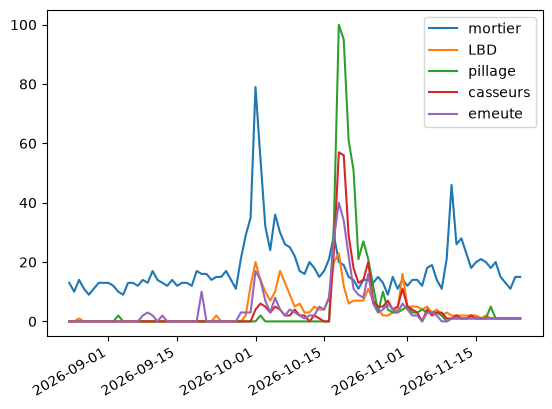

In [7]:
G_trend = Google_Trends()

# Mots de Recherche
mots_contexte = []

mots_de_recherche = ["mortier", "LBD", 'pillage', "casseurs", "emeute"]

# Résultat de la recherche
df = G_trend.get_trends(mots_de_recherche, geo="FR", timeframe="today 3-m")

autres_cols = df.drop(columns=["Time"])
plt.plot(df["Time"], autres_cols, label=autres_cols.columns)
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

Pour mieux approximer le nombre de recheres sur les émeutes, nous regardons l'intérêt des internautes pours plusieurs mots clés autour de ce thème. Nous normalisons ensuite le nombre de requête de chaque mot à 100 pour que chacun ait autant d'importance dans l'indice final, étant composé de la moyenne des requettes normalisées. \
Sans normalisations, certains mots clés effaceraient les autres, comme le montre le graphique précédent. Dans notre cas, la recherche pour "mortier" est plus présente mais aussi plus bruitée.

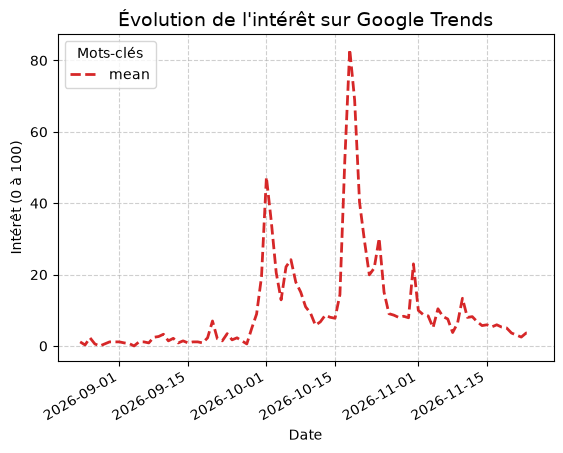

In [8]:
# Récupération des données, normalisation et création d'une moyenne de recherche
df = G_trend.normalisation(df)
df = G_trend.add_average(df)

df_google_trends = df[["mean", "Time"]]

G_trend.plot(df_google_trends)

## Comparer GDELT et Google Trends

Maintenant que nous avons les deux bases d'émeutes, nous pouvons mettre en perspective les résultats trouvés. Les évenements trouvés sur GDELT étant discrets, pour avoir une meilleure représentation des périodes d'émeutes, nous allons aggréger le nombre d'articles parus sur des périodes de 3 jours.

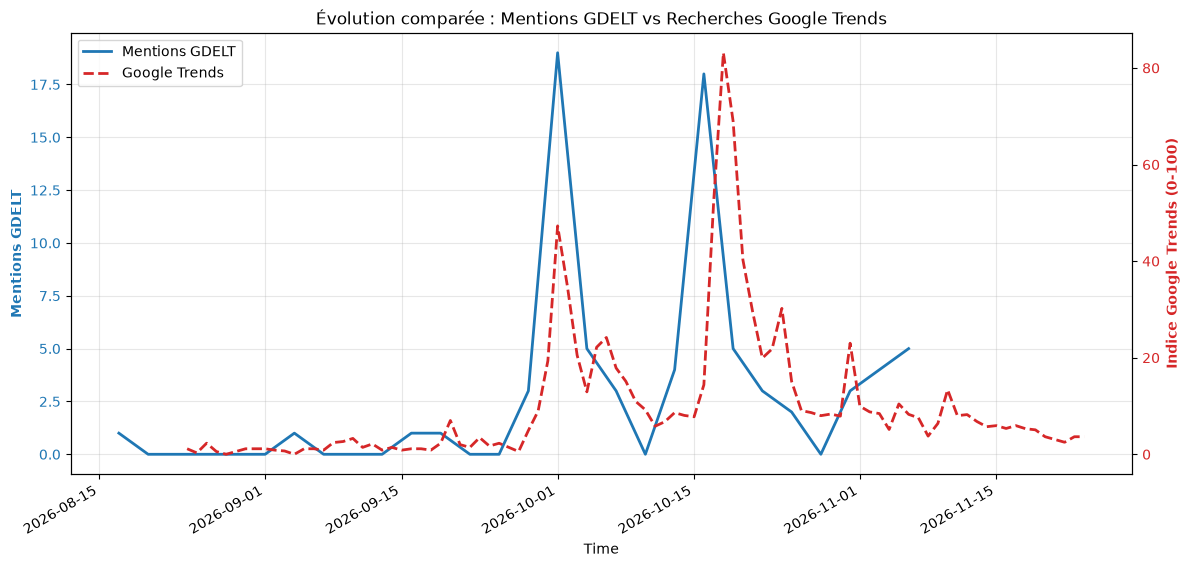

In [9]:
def comparer_GDELT_Gtrend(G_trend_class, df_gdelt, aggregation_periode = "3D", afficher=True):
    # Pour aggréger par x jours ( mettre "xD" en periode ou 'W-SUN' pour une semaine)
    df_gdelt_weekly = (
        df_gdelt
        .resample(aggregation_periode, on='Time')
        .size()
        .reset_index(name='nb_emeutes')
    )

    if afficher: G_trend_class.comparer_GDELT_plot(df_gdelt_weekly)

    return df_gdelt_weekly

# Bien définir la date
if not "Time"  in df_GDELT_small.columns:
    df_GDELT_small = df_GDELT_small.rename(columns={'observed_at': 'Time'})
    df_GDELT_small['Time'] = pd.to_datetime(df_GDELT_small['Time']).dt.tz_localize(None)


df_gdelt_weekly_small = comparer_GDELT_Gtrend(G_trend, df_GDELT_small, "3D")

Pour comparer à la table entière, sur un intervalle de 4 ans, on utilise la même fonction:

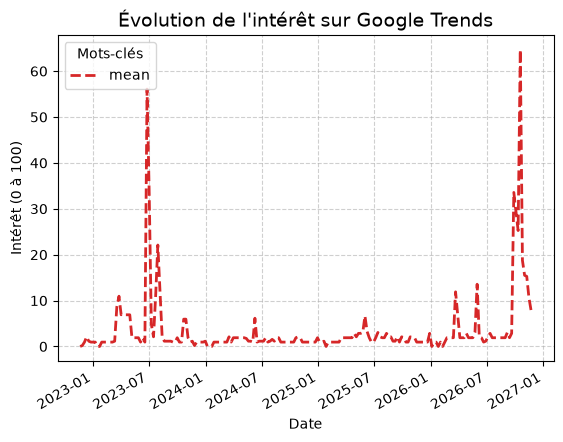

In [10]:
# On doit récupérer à nouveau les données sur plus d'années
G_trend_large = Google_Trends()


# Récupération des données, normalisation et création d'une moyenne de recherche
df_large = G_trend_large.get_trends(mots_de_recherche, geo="FR", timeframe="today 4-y")
df_large = G_trend_large.normalisation(df_large)
df_large = G_trend_large.add_average(df_large)

df_google_trends_large = df_large[["mean", "Time"]]

G_trend_large.plot(df_google_trends_large) # on affiche ce résultat

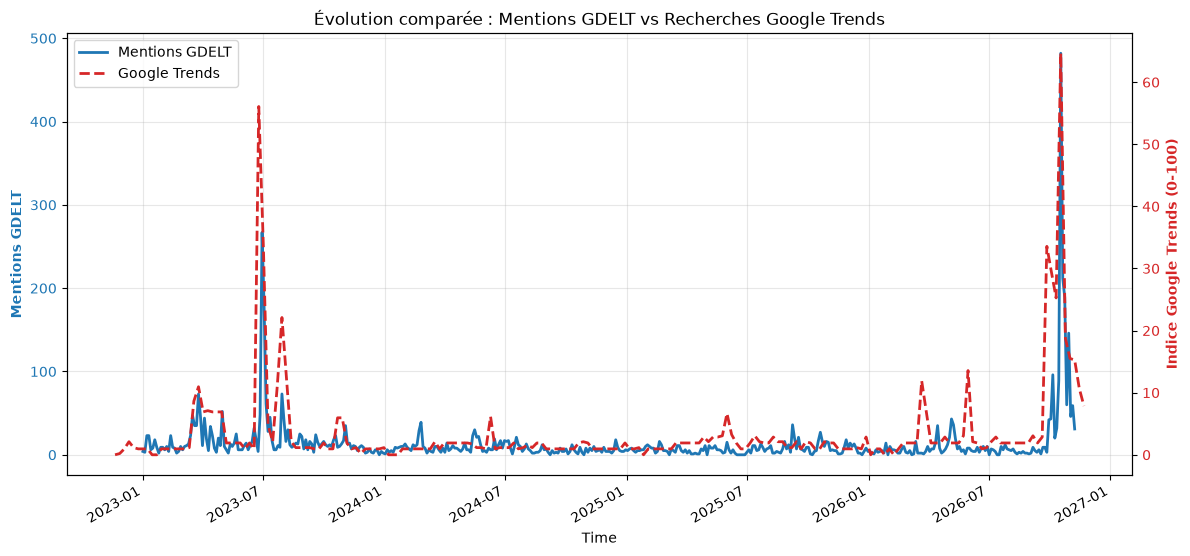

In [11]:
# Comparer
df_GDELT_large['Time'] = pd.to_datetime(df_GDELT_large['SQLDATE'].astype(str), format='%Y%m%d')
df_gdelt_weekly_large = comparer_GDELT_Gtrend(G_trend_large, df_GDELT_large, "3D")

### Remarque
On aperçoit bien une corrélation entre les résultats des données de recherche des utilisateurs (Google Trends) et le nombre de parutions dans les journeaux d'articles mentionnant des émeutes (GDELT). Trois périodes se distinguent: entre mars et août 2023 et fin 2026. Le premier correspond aux mouvements contre la réforme des retraites et surtout aux durcissement des mobilisations pendant la periode de mars 2023. Le second correspond aux évenements survenus après la mort de Nahel Merzouk en juin 2023. Le dernier est lié aux mouvements étudiants.

Si on met maintenant les graphiques de Google Trends et les deux graphiques de GDELT à côté, on obtient:

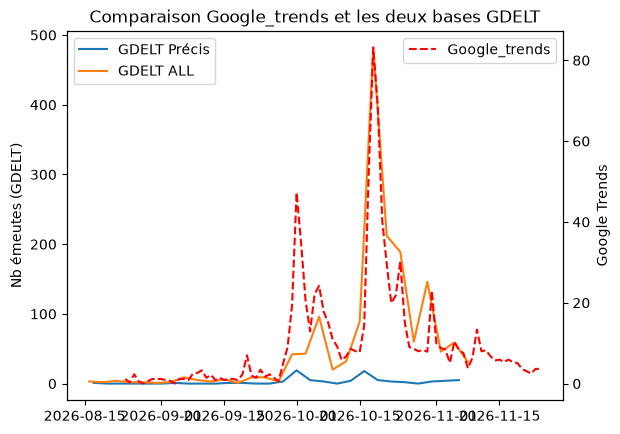

In [12]:
df_GDELT_large_filtre = df_gdelt_weekly_large[df_gdelt_weekly_large["Time"] > "2026-08-15"]

# Axe de gauche : les deux bases GDELT
plt.plot(df_gdelt_weekly_small["Time"], df_gdelt_weekly_small["nb_emeutes"], label="GDELT Précis")
plt.plot(df_GDELT_large_filtre["Time"], df_GDELT_large_filtre["nb_emeutes"], label="GDELT ALL")
plt.ylabel("Nb émeutes (GDELT)")
plt.legend(loc="upper left")

# Axe de droite : Google Trends
plt.twinx()
plt.plot(df_google_trends["Time"], df_google_trends["mean"], color="red", linestyle="--", label="Google_trends")
plt.ylabel("Google Trends")
plt.legend(loc="upper right")

plt.title("Comparaison Google_trends et les deux bases GDELT")
plt.show()

### Remarques

La base plus précise s'accorde mieux avec les résultats google Trends, notamment au niveau du premier pic; mais ignore le second et comprend bien moins de données. 

Comparons, sur la même période le nombre de points :

In [13]:
nSmall = len(df_GDELT_small[df_GDELT_small["Time"]> "2026-08-15"])
nLarge = len(df_GDELT_large[df_GDELT_large["Time"]> "2026-08-15"])
print("Nombre de lignes pour la base GDELT précise:", nSmall)
print("Nombre de lignes pour la base GDELT entière:", nLarge)
print("C'est", round(nLarge/nSmall * 100)/100, "fois plus")

Nombre de lignes pour la base GDELT précise: 78
Nombre de lignes pour la base GDELT entière: 1608
C'est 20.62 fois plus


En mettant au même niveau les deux courbes GDELT:

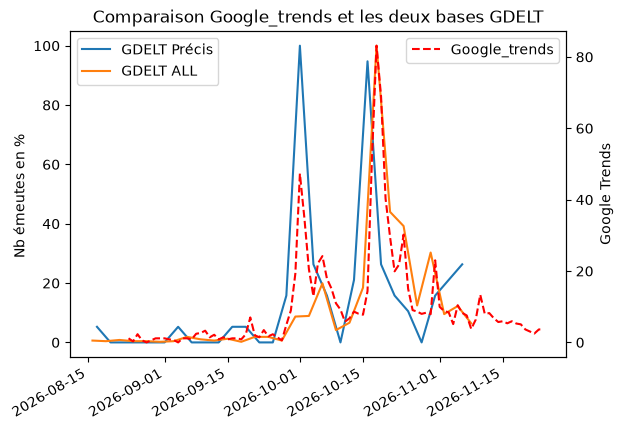

In [14]:
# Axe de gauche : les deux bases GDELT

GDELT_small_normalized = df_gdelt_weekly_small["nb_emeutes"]/df_gdelt_weekly_small["nb_emeutes"].max()*100
GDELT_large_normalized = df_GDELT_large_filtre["nb_emeutes"]/df_GDELT_large_filtre["nb_emeutes"].max()*100

plt.plot(df_gdelt_weekly_small["Time"], GDELT_small_normalized, label="GDELT Précis")
plt.plot(df_GDELT_large_filtre["Time"], GDELT_large_normalized, label="GDELT ALL")
plt.ylabel("Nb émeutes en % ")
plt.legend(loc="upper left")

# Axe de droite : Google Trends
plt.twinx()
plt.plot(df_google_trends["Time"], df_google_trends["mean"], color="red", linestyle="--", label="Google_trends")
plt.ylabel("Google Trends")
plt.legend(loc="upper right")
plt.gcf().autofmt_xdate()
plt.title("Comparaison Google_trends et les deux bases GDELT")
plt.show()

En aggrandissant la table plus précise, on remarque que celle-ci décrit mieux le début des manifestations qui restent peu marqués sur la table entière. \
Certaines données imprécises se cachent dans cette même table entière. Pour le vérifier, faisons un test: affichons les articles contenant un certain mot clé dans leur URL.

In [17]:
mot_recherche_URL = "couvre" # essayer avec frankfurt, tornade, ukraine

urls = df_GDELT_large.loc[df_GDELT_large['SOURCEURL'].str.contains(mot_recherche_URL, case=False, na=False), 'SOURCEURL']
for url in urls.head(10):
    print(url)

https://www.tf1info.fr/justice-faits-divers/on-l-a-trouve-la-40-ans-apres-l-un-des-decouvreurs-du-fabuleux-tresor-de-lava-felix-biancamaria-de-retour-au-tribunal-a-marseille-lundi-29-fevrier-2024-2283991.html
https://www.lindependant.fr/2023/07/01/mort-de-nahel-17-ans-a-nanterre-un-couvre-feu-a-marseille-pour-eviter-que-les-commercants-ne-se-defendent-eux-memes-11314438.php
https://www.cnews.fr/france/2026-10-20/violences-urbaines-un-nouveau-couvre-feu-nocturne-decrete-partir-de-ce-soir-dans
https://www.cnews.fr/france/2026-10-20/violences-urbaines-un-nouveau-couvre-feu-nocturne-decrete-partir-de-ce-soir-dans
https://www.lalibre.be/international/europe/2026/10/23/lespagne-decouvre-un-appel-djihadiste-a-attaquer-la-police-et-les-manifestants-en-europe-IWMPHF3EXVH37JT62D7KWAKPLA/
https://www.boursorama.com/actualite-economique/actualites/violences-l-etat-au-chevet-des-commercants-les-couvre-feux-prolonges-60c699cc70d40b95435778ac1a7eb267
https://www.bfmtv.com/societe/manifestations/crite

Voici quelques articles que l'on trouve:
- "Guerre en Ukraine : Zelensky dénonce un « chantage » de l’Europe sur l’oléoduc Droujba, au cœur d’une dispute avec la Hongrie"
- "Une impressionnante tornade ravage un village en France : 41 blessés"
- Des articles sur la mise en place d'un couvre feu suite aux émeutes, ne concernant pas directement un évenement émeute mais une réaction politique aux émeutes.

On voit aisément que cette table posera des problèmes pour l'analyse géographique qui suit, sachant que tous ces évenements sont situés dans la base de donnée dans des communes francaises ayant apparemment aucun lien avec les événements racontés et les émeutes. Ces articles décrivent souvent des émeutes étrangères dont les auteurs font référence à la France. On ne peut donc pas s'assurer d'une cohérence entre la parution de ces articles et l'avenement d'une émeute à la même période en France. \
Nous continuerons ces travaux en utilisant la base GDELT plus petite mais déjà nettoyée.

## Données sociales

## Peut on trouver une relation ?

## Limites et Conclusion 

Avant de conclure cette étude, nuançons les résultats trouvés et détaillons les limites de ce travail.

1. Des données implicites: \
La difficulté de ce travail a été de modéliser les émeutes en France. Aucune base de donnée libre d'accès recense fidèlement ces évènements. Nous avons donc reconstruits des estimateurs à partir des publications dans les médias et des recherches des utilisateurs. Néanmoins, ces mesures restent imparfaites.

2. Des analyses simplifiées: \
Nous savons que d'autres variables géographiques et sociales peuvent expliquer les émeutes comme la perception d'inégalités, le pouvoir d'achat moyen dans un territoire... Les résulats trouvés pourraient se révéler provenant d'une corrélation plus que d'une causalité. 

